In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import accuracy_score,confusion_matrix
sns.set()

In [ ]:
data=pd.read_csv("/content/movies_classification.csv")
print(data.head())
print(data.info())
print(data.isna().sum())

   Marketing expense  Production expense  ...  Collection  Start_Tech_Oscar
0            20.1264               59.62  ...       48000                 1
1            20.5462               69.14  ...       43200                 0
2            20.5458               69.14  ...       69400                 1
3            20.6474               59.36  ...       66800                 1
4            21.3810               59.36  ...       72400                 1

[5 rows x 19 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Marketing expense    506 non-null    float64
 1   Production expense   506 non-null    float64
 2   Multiplex coverage   506 non-null    float64
 3   Budget               506 non-null    float64
 4   Movie_length         506 non-null    float64
 5   Lead_ Actor_Rating   506 non-null    float64
 6   Lead_Actres

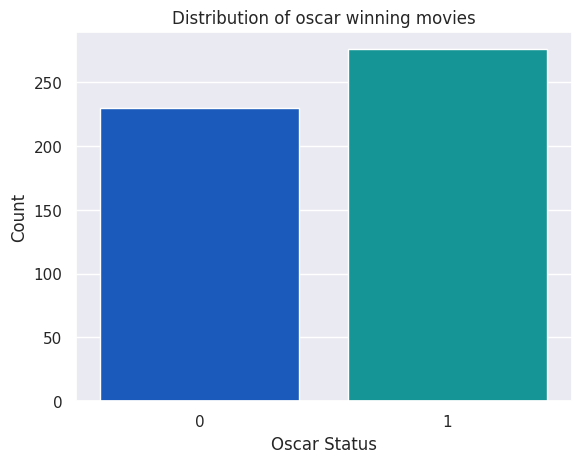

In [ ]:
#EDA
target=data["Start_Tech_Oscar"]
sns.countplot(x=target, hue=target, palette='winter', legend=False)
plt.xlabel("Oscar Status")
plt.ylabel("Count")
plt.title("Distribution of oscar winning movies")
plt.show()

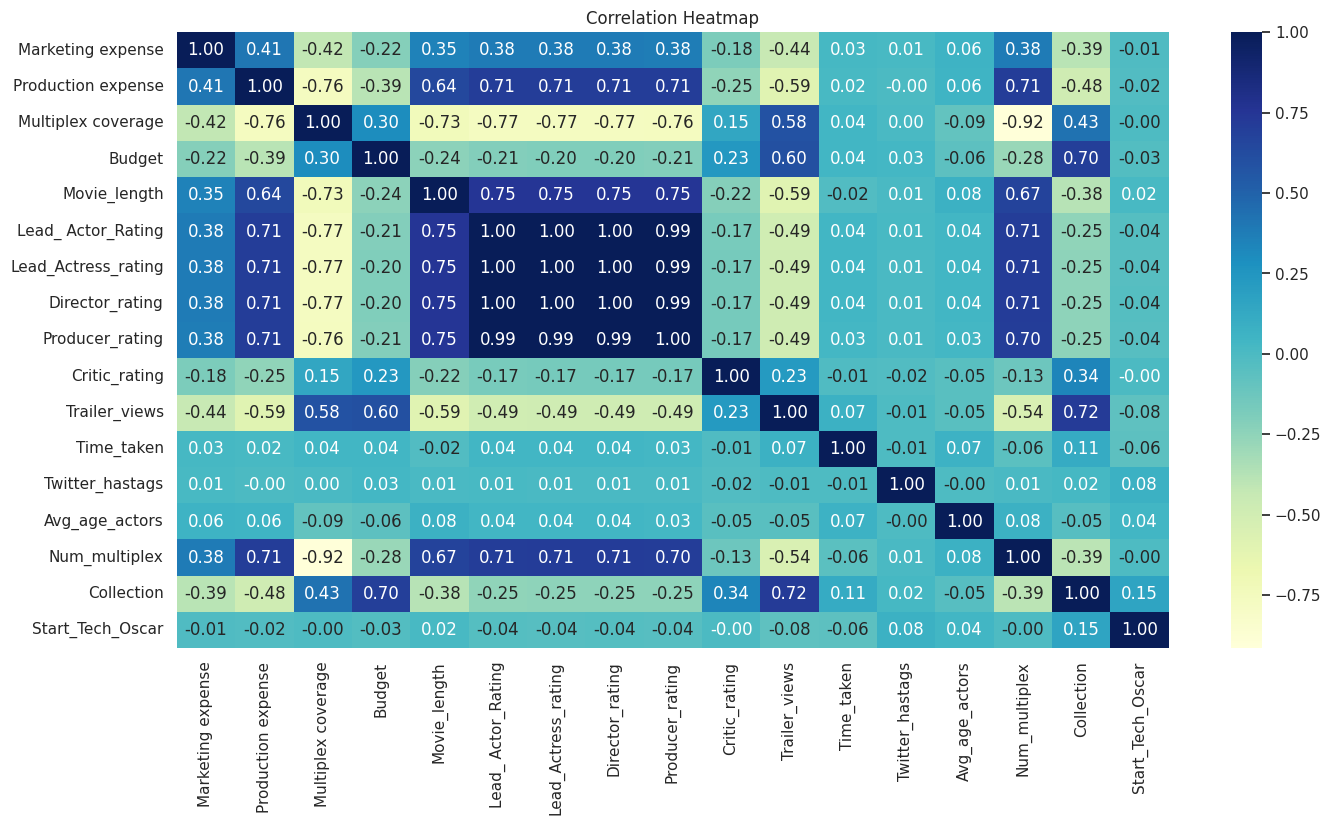

In [ ]:
plt.figure(figsize=(16,8))
numeric_df=data.select_dtypes(include=[np.number])

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='YlGnBu',
    fmt='.2f'
)
plt.title("Correlation Heatmap")
plt.show()

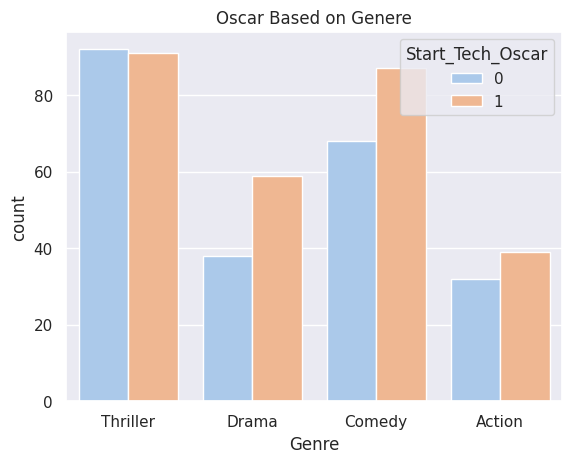

In [ ]:
sns.countplot(
    x='Genre',
    data=data,
    hue='Start_Tech_Oscar',
    palette='pastel'
)
plt.title("Oscar Based on Genere")
plt.show()

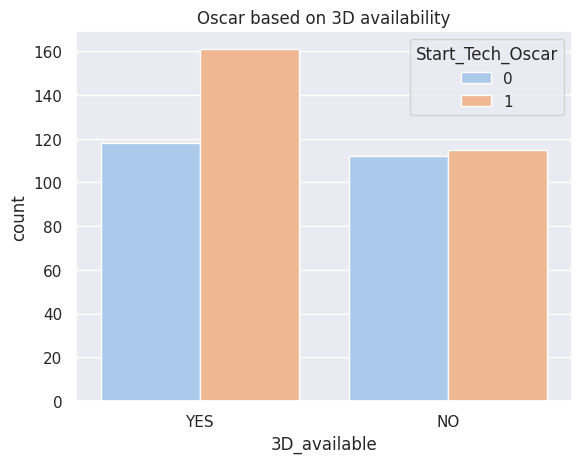

In [ ]:
sns.countplot(
    x='3D_available',
    data=data,
    hue='Start_Tech_Oscar',
    palette='pastel'
)
plt.title("Oscar based on 3D availability")
plt.show()

In [ ]:
#histogram and density graph by our own

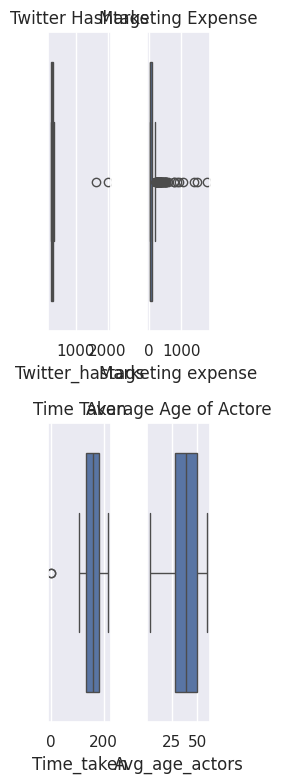

In [ ]:
plt.figure(figsize=(2,8))
plt.subplot(2,2,1)
sns.boxplot(x=data["Twitter_hastags"])
plt.title("Twitter Hashtags")

plt.subplot(2,2,2)
sns.boxplot(x=data["Marketing expense"])
plt.title("Marketing Expense")

plt.subplot(2,2,3)
sns.boxplot(x=data["Time_taken"])
plt.title("Time Taken")


plt.subplot(2,2,4)
sns.boxplot(x=data["Avg_age_actors"])
plt.title("Avarage Age of Actore")

plt.tight_layout()
plt.show()

In [ ]:
#Winsorization for outlier treatment
from feature_engine.outlier import Winsorizer

winsor=Winsorizer(
    capping_method='iqr',
    tail='both',
    fold=1.5,
    variables=['Twitter_hastags',
               'Marketing expense',
               'Time_taken',
               'Avg_age_actors']
)
data=winsor.fit_transform(data)

ModuleNotFoundError: No module named 'feature_engine.outlier'

In [ ]:
skew_df=pd.DataFrame(
    data.select_dtypes(np.number).columns,
    columns=['Feature']
)

skew_df['skew']=skew_df['Feature'].apply(
    lambda feature: skew(data[feature])
)

skew_df['Absolute skew']=skew_df['skew'].abs()

skew_df['skewed']=skew_df['Absolute skew']>=0.5
print(skew_df)

                Feature       skew  Absolute skew  skewed
0     Marketing expense   5.207652       5.207652    True
1    Production expense   0.294146       0.294146   False
2    Multiplex coverage  -0.727144       0.727144    True
3                Budget   0.402415       0.402415   False
4          Movie_length  -0.597186       0.597186    True
5    Lead_ Actor_Rating  -1.007579       1.007579    True
6   Lead_Actress_rating  -1.004502       1.004502    True
7       Director_rating  -1.000870       1.000870    True
8       Producer_rating  -1.001700       1.001700    True
9         Critic_rating   0.175616       0.175616   False
10        Trailer_views  -0.841327       0.841327    True
11           Time_taken  -0.477741       0.477741   False
12      Twitter_hastags  13.749637      13.749637    True
13       Avg_age_actors   0.012932       0.012932   False
14        Num_multiplex   0.532636       0.532636    True
15           Collection   1.107616       1.107616    True
16     Start_T

In [ ]:
for column in skew_df.query("skewed==True")['Feature'].values:
  if column !="Start_Tech_Oscar":
    data[column]=np.log1p(data[column])
  print(data.head())

   Marketing expense  Production expense  ...  Collection  Start_Tech_Oscar
0           3.050523               59.62  ...       48000                 1
1           3.070199               69.14  ...       43200                 0
2           3.070181               69.14  ...       69400                 1
3           3.074885               59.36  ...       66800                 1
4           3.108212               59.36  ...       72400                 1

[5 rows x 19 columns]
   Marketing expense  Production expense  ...  Collection  Start_Tech_Oscar
0           3.050523               59.62  ...       48000                 1
1           3.070199               69.14  ...       43200                 0
2           3.070181               69.14  ...       69400                 1
3           3.074885               59.36  ...       66800                 1
4           3.108212               59.36  ...       72400                 1

[5 rows x 19 columns]
   Marketing expense  Production expense  

In [ ]:
data_encoded=data.copy()
data_encoded=pd.get_dummies(data_encoded,drop_first=True)
print(data_encoded.head())

   Marketing expense  Production expense  ...  Genre_Drama  Genre_Thriller
0           3.050523               59.62  ...        False            True
1           3.070199               69.14  ...         True           False
2           3.070181               69.14  ...        False           False
3           3.074885               59.36  ...         True           False
4           3.108212               59.36  ...         True           False

[5 rows x 21 columns]


In [ ]:
y=data_encoded["Start_Tech_Oscar"]
x=data_encoded.drop(columns=["Start_Tech_Oscar"])
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)
x_scaled=pd.DataFrame(
    x_scaled,
    columns=x.columns
)
print(x_scaled.head())

   Marketing expense  Production expense  ...  Genre_Drama  Genre_Thriller
0          -0.784675           -1.287909  ...    -0.486995        1.328543
1          -0.765110           -0.593381  ...     2.053411       -0.752704
2          -0.765128           -0.593381  ...    -0.486995       -0.752704
3          -0.760450           -1.306878  ...     2.053411       -0.752704
4          -0.727311           -1.306878  ...     2.053411       -0.752704

[5 rows x 20 columns]


In [ ]:
y=data_encoded["Start_Tech_Oscar"]
x=data_encoded.drop("Start_Tech_Oscar",axis=1)

scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)
x_scaled=pd.DataFrame(
    x_scaled,
    columns=x.columns
    )
print(x_scaled.head())

   Marketing expense  Production expense  ...  Genre_Drama  Genre_Thriller
0          -0.784675           -1.287909  ...    -0.486995        1.328543
1          -0.765110           -0.593381  ...     2.053411       -0.752704
2          -0.765128           -0.593381  ...    -0.486995       -0.752704
3          -0.760450           -1.306878  ...     2.053411       -0.752704
4          -0.727311           -1.306878  ...     2.053411       -0.752704

[5 rows x 20 columns]


In [ ]:
x_train,x_test,y_train,y_test=train_test_split(
    x_scaled,
    y.astype(int),
    test_size=0.2,
    stratify=y,
    random_state=42
)
print("Training Shape:",x_train.shape)
print("Testing Shape:",x_test.shape)

Training Shape: (404, 20)
Testing Shape: (102, 20)


In [ ]:
ada_clf=AdaBoostClassifier(
    learning_rate=0.02,
    n_estimators=500,
    random_state=42
)
ada_clf.fit(x_train,y_train)
y_pred_test=ada_clf.predict(x_test)

print(accuracy_score(y_test,y_pred_test))
print(confusion_matrix(y_test,y_pred_test))

0.5490196078431373
[[ 0 46]
 [ 0 56]]


In [ ]:
y_pred_train=ada_clf.predict(x_train)
training_accuracy=accuracy_score(y_train,y_pred_train)
print("\nTraining Accuracy:",training_accuracy)


Training Accuracy: 0.5445544554455446


In [ ]:
'''
adaboost imporoves classification performance.
collection and rating influence oscar prediction,
twitter hashtags have weaker impact
feature engineering and preprocessing improve accuracy
'''